In [1]:
import torch
from torch import nn
import torchvision
from torchvision import transforms
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [2]:
print(torch.__version__)
print(torchvision.__version__)

2.14.0+cu130
0.29.1+cu130


In [3]:
train_data=datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

test_data=datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [4]:
len(train_data),len(test_data)

(60000, 10000)

In [5]:
image,label=train_data[0]
[image,label]

[tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [6]:
class_names=train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [7]:
class_to_idx=train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [8]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [9]:
image.shape,label

(torch.Size([1, 28, 28]), 9)

In [10]:
print(f"Image shape: {image.shape} -> [color_channels,height,width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) -> [color_channels,height,width]
Image label: Ankle boot


In [11]:
image,label=train_data[0]
print(f"Image shape: {image.shape}")
print(f"Image shape: {image.squeeze().shape}")

Image shape: torch.Size([1, 28, 28])
Image shape: torch.Size([28, 28])


Text(0.5, 1.0, '9')

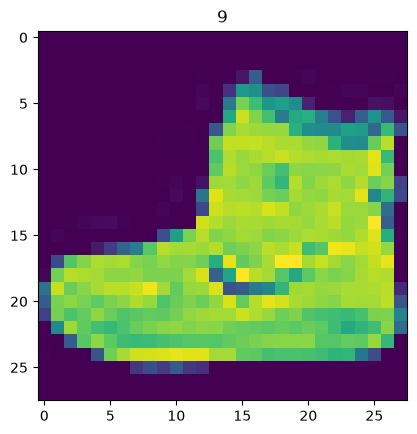

In [12]:

plt.imshow(image.squeeze())
plt.title(label)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

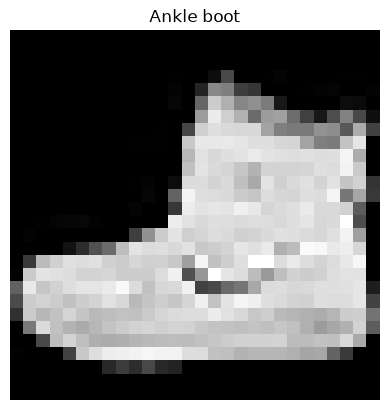

In [13]:
plt.imshow(image.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)

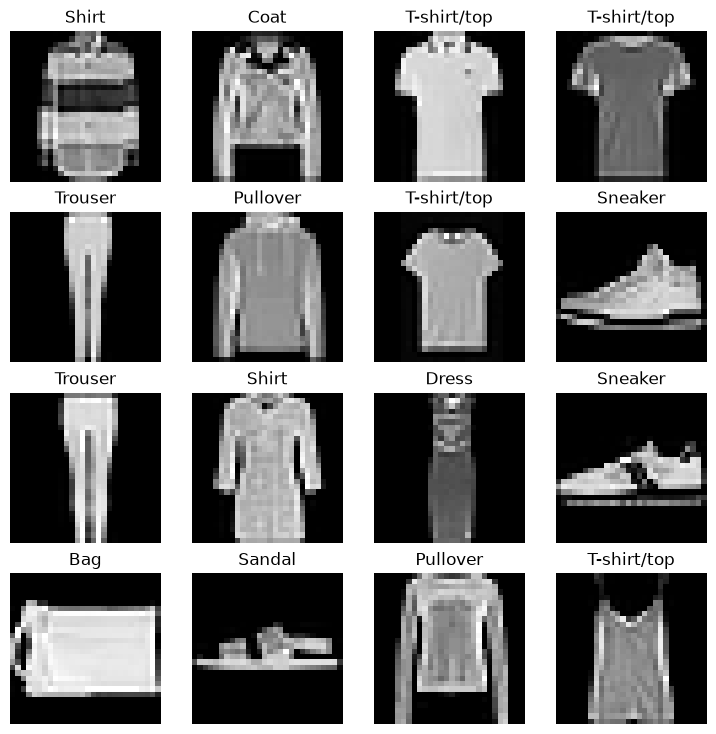

In [14]:

fig=plt.figure(figsize=(9,9))
rows,cols=4,4
for i in range(1,rows*cols+1):
    random_idx=torch.randint(0,len(train_data),size=[1]).item()
    img,label=train_data[random_idx]
    fig.add_subplot(rows,cols,i)
    plt.imshow(img.squeeze(),cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

In [15]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [16]:
test_data

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [17]:
from torch.utils.data import DataLoader

BATCH_SIZE=32
train_dataloader=DataLoader(dataset=train_data,
                            batch_size=BATCH_SIZE,
                            shuffle=True)
test_dataloader=DataLoader(dataset=test_data,
                           batch_size=BATCH_SIZE,
                           shuffle=False)

train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7db77250b200>,
 <torch.utils.data.dataloader.DataLoader at 0x7db671127ce0>)

In [18]:
print(f"Dataloaders: {train_dataloader,test_dataloader}")
print(f"Dataloaders: {len(train_dataloader),len(test_dataloader)}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7db77250b200>, <torch.utils.data.dataloader.DataLoader object at 0x7db671127ce0>)
Dataloaders: (1875, 313)


In [19]:
train_features_batch,train_labels_batch=next(iter(train_dataloader))
train_features_batch.shape,train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 9,label size: torch.Size([])


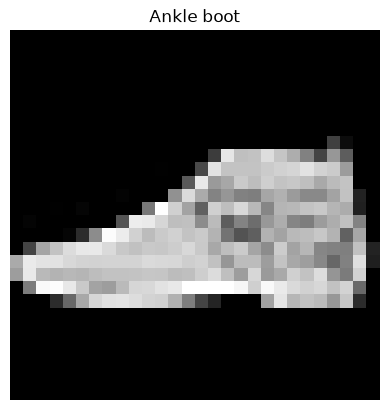

In [20]:
torch.manual_seed(42)
random_idx=torch.randint(0,len(train_features_batch),size=[1]).item()
img,label=train_features_batch[random_idx],train_labels_batch[random_idx]
plt.imshow(img.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)
print(f"Image size: {img.shape}")
print(f"Label: {label},label size: {label.shape}")

In [21]:
flatten_model=nn.Flatten()


x=train_features_batch[0]

In [22]:
#x.shape

output=flatten_model(x)
output.shape

torch.Size([1, 784])

In [23]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self,input_shape,hidden_units,output_shape):
        super().__init__()

        self.layer_stack=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,out_features=hidden_units),
            nn.Linear(in_features=hidden_units,out_features=output_shape),
        )

    def forward(self,X):
        return self.layer_stack(X)

In [24]:
torch.manual_seed(42)

model_0=FashionMNISTModelV0(
    input_shape=784,
    hidden_units=10,
    output_shape=len(class_names)
)

model_0.to("cpu")

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [25]:
dummy_x=torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [26]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

In [27]:
import requests
from pathlib import Path

if Path("helper_functions.py").is_file():
    print("helper_functions.py already exsists, skipping download....")
else:
    print("Downloading helper_functions.py")
    request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    with open("helper_functions.py","wb") as f:
        f.write(request.content)

helper_functions.py already exsists, skipping download....


In [28]:
from helper_functions import accuracy_fn

loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.1)

In [29]:
from timeit import default_timer as timer

def print_train_time(start:float,end:float,device:torch.device=None):
    total_time=end-start

    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

In [30]:
start_time=timer()

end_time=timer()
print_train_time(start=start_time,end=end_time,device="cpu")

Train time on cpu: 0.000 seconds


4.5574000068882015e-05

In [31]:
from tqdm.auto import tqdm

torch.manual_seed(42)
train_time_start_on_cpu=timer()


epocs=5

for epoc in tqdm(range(epocs)):

    print(f"Epoc: {epoc}\n------")

    train_loss=0

    for batch,(X,y) in enumerate(train_dataloader):
        model_0.train()

        y_pred=model_0(X)

        loss=loss_fn(y_pred,y)
        train_loss+=loss.item()

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        if batch %400==0:
            print(f"Looked at {batch*len(X)}/{len(train_dataloader.dataset)} samples ")

    train_loss /=len(train_dataloader)

    test_loss,test_acc=0,0

    model_0.eval()

    with torch.inference_mode():

        for X_test, y_test in test_dataloader:
            test_pred=model_0(X_test)

            test_loss+=loss_fn(test_pred,y_test)

            test_acc+=accuracy_fn(y_true=y_test,y_pred=test_pred.argmax(dim=1))

        test_loss/=len(test_dataloader)

        test_acc/=len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.4f} | Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

train_time_end_on_cpu=timer()

total_train_time_model_0=print_train_time(
    start=train_time_start_on_cpu,
    end=train_time_end_on_cpu,
    device=str(next(model_0.parameters()).device)
)



/home/hasan-hafizov/miniconda3/envs/audio/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
  0%|          | 0/5 [00:00<?, ?it/s]

Epoc: 0
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 20%|██        | 1/5 [00:05<00:22,  5.69s/it]


Train loss: 0.5904 | Test loss: 0.5095, Test acc: 82.0387
Epoc: 1
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 40%|████      | 2/5 [00:11<00:17,  5.83s/it]

...


Train loss: 0.4550 | Test loss: 0.4766, Test acc: 83.4265
Epoc: 3
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 80%|████████  | 4/5 [00:24<00:06,  6.37s/it]


Train loss: 0.4425 | Test loss: 0.4631, Test acc: 83.7460
Epoc: 4
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


100%|██████████| 5/5 [00:30<00:00,  6.03s/it]


Train loss: 0.4358 | Test loss: 0.4687, Test acc: 83.2668
Train time on cpu: 30.164 seconds


In [32]:
torch.manual_seed(42)

def eval_model(model:torch.nn.Module,data_loader: torch.utils.data.DataLoader,loss_fn: torch.nn.Module,accuracy_fn):
    loss, acc = 0, 0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:
            y_pred=model(X)

            loss+=loss_fn(y_pred,y)

            acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,"model_loss":loss.item(),"model_acc":acc}

model_0_results=eval_model(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4686938524246216,
 'model_acc': 83.2667731629393}

In [33]:
import torch

device="cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [34]:
class FashionMinist(nn.Module):
    def __init__(self,input_layer,hidden_layer,output_layer):
        super().__init__()
        self.stacks_layer=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_layer,out_features=hidden_layer),
            nn.ReLU(),
            nn.Linear(in_features=hidden_layer,out_features=output_layer),
            nn.ReLU()
        )
    def forward(self,x:torch.Tensor):
        return self.stacks_layer(x)
    

In [35]:
next(model_0.parameters()).device

device(type='cpu')

In [36]:
device

'cuda'

In [37]:
torch.manual_seed(42)

model_1=FashionMinist(784,10,len(class_names)).to(device)

In [38]:
next(model_1.parameters()).device

device(type='cuda', index=0)

In [39]:
from helper_functions import accuracy_fn

loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.01)

In [40]:
torch.manual_seed(42)


In [41]:
def train_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device=device):
    train_loss,train_acc=0,0

    model.train()

    for batch,(X,y) in enumerate(data_loader):

        X,y=X.to(device),y.to(device)

        y_pred=model(X)

        loss=loss_fn(y_pred,y)
        train_loss+=loss.item()
        train_acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    train_loss /=len(data_loader)
    train_acc /=len(data_loader)

    print(f"Train loss: {train_loss:.5f} | Train acc: {train_acc:.5f}%")

In [42]:
def test_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               accuracy_fn,
               device:torch.device=device):

    test_loss,test_acc=0,0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:
            X,y=X.to(device),y.to(device)

            test_pred=model(X)

            test_loss+=loss_fn(test_pred,y)
            test_acc+=accuracy_fn(y,test_pred.argmax(dim=1))
        test_loss/=len(data_loader)
        test_acc/=len(data_loader)

        print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%")

In [43]:
torch.manual_seed(42)
train_time_start_on_gpu=timer()


epocs=6
for epoc in tqdm(range(epocs)):
    print(f"Epoc: {epoc}\n-------------------")
    train_step(model=model_1,data_loader=train_dataloader,loss_fn=loss_fn,optimizer=optimizer,accuracy_fn=accuracy_fn,device=device)


    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end_on_gpu=timer()

total_train_time_model_1=print_train_time(start=train_time_start_on_gpu,end=train_time_end_on_gpu,device=device)

  0%|          | 0/6 [00:00<?, ?it/s]

Epoc: 0
-------------------
Train loss: 1.42179 | Train acc: 54.28667%


 17%|█▋        | 1/6 [00:07<00:38,  7.74s/it]

Test loss: 1.12168 | Test acc: 62.15%
Epoc: 1
-------------------
Train loss: 1.03359 | Train acc: 64.61167%


 33%|███▎      | 2/6 [00:14<00:28,  7.01s/it]

...

Test loss: 0.93870 | Test acc: 65.94%
Epoc: 4
-------------------
Train loss: 0.91089 | Train acc: 67.04167%


 83%|████████▎ | 5/6 [00:38<00:08,  8.11s/it]

Test loss: 0.92726 | Test acc: 65.99%
Epoc: 5
-------------------
Train loss: 0.89804 | Train acc: 67.27667%


100%|██████████| 6/6 [00:46<00:00,  7.77s/it]

Test loss: 0.91716 | Test acc: 66.25%
Train time on cuda: 46.629 seconds


In [44]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4686938524246216,
 'model_acc': 83.2667731629393}

In [45]:
total_train_time_model_0

30.163645301999622

In [48]:
torch.manual_seed(42)

def eval_model(model:torch.nn.Module,data_loader: torch.utils.data.DataLoader,loss_fn: torch.nn.Module,accuracy_fn):
    loss, acc = 0, 0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:

            X,y=X.to(device),y.to(device)
            y_pred=model(X)

            loss+=loss_fn(y_pred,y)

            acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,"model_loss":loss.item(),"model_acc":acc}

In [53]:
model_1_results=eval_model(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

In [54]:
model_1_results

{'model_name': 'FashionMinist',
 'model_loss': 0.9171638488769531,
 'model_acc': 66.25399361022365}